# Subseasonal skill of tropical winds

## Purpose

Daily spatial anomaly correlation and RMSE of the tropical (20S-20N) 850- and 200-hPa zonal wind against ERA5 over the first `LEAD_DAYS_MAX` days.

## Inputs

Model: the 2012-2013 AMIP hindcasts under `INPUT_DATA_ROOT/<case>/post/atm/180x360_aave` (experiments and initial states in `configs/hind_experiment_config.py`). Daily U850, U200. Reference: ERA5 daily U850/U200 (daily means of `OBSERVATION_ROOT/ERA5/1x1/6hourly`; variables without a reference are skipped).

## Method

Anomalies per `ANOM_METHOD`: `harmonics` (default; record mean plus 3 annual harmonics, valid from day 0), `bandpass_20_100` (Lanczos, 201 taps: model leads < 100 days are lost because the run starts at the initial date), or `rm60`. Daily cos-lat weighted ACC and RMSE, `SMOOTH_DAYS` running means, and window-mean ACC with a moving-block bootstrap 95% CI; the first window starts at lead 0, where the initial state matters most. Time scales: day-0 ACC, e-folding lead (ACC < ACC(0)/e), and the lead from which the DART-atm runs' mean ACC stays above the ERA5-atm runs' (`CROSSOVER`). Attribution (`util/hind_factorial.py`): every score is fitted as μ + atm + lnd over the 8 single runs; the interaction residual is the noise floor that sets the 95% interval of each effect.

Caveat: ERA5 is both the verifying analysis and the ERA5 runs' initial state, so their day-0 ACC is favoured. No independent daily reanalysis for 2012 is in the reference archive (MERRA-2 there is monthly).

## Outputs

`data/hind_atm_eval/wind/wind_skill_<VAR>.nc`, `wind_skill_windows.csv`, `wind_skill_scores.csv` (window ACC and time scales per experiment), `wind_skill_effects.csv` (factorial effects); figures in `figure/hind_atm_eval/wind/`:

1. Smoothed ACC/RMSE and window-mean ACC per experiment.
2. Daily ACC by atmosphere initial state and the DART − ERA5 effect with its 95% interval.
3. Factorial scorecard of the window ACCs and time scales.

## 1. Libraries

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr
from IPython.display import display

## 2. User setup

Paths and run options. Edit this cell for normal changes; it holds plain values only, so `papermill -p` overrides work.

In [2]:
INPUT_DATA_ROOT = Path("/global/cfs/cdirs/m4849/zhan391/eam_hindcast")
WORK_DIR = Path("/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026")
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")  # reference-data archive
WORKFLOW_NAME = "hind_atm_eval"

EXPERIMENTS = ("CTRL", "DARTOP", "ERA5OP", "ERA5DL", "ERA5BL", "DARTBL", "DARTBA", "DARTAE")
VARIABLES = ("U850", "U200")
START, END = "2012-01-01", "2013-12-31"
INIT_DATE = "2012-01-01"
LAT_RANGE = (-20.0, 20.0)
LEAD_DAYS_MAX = 120
ANOM_METHOD = "harmonics"   # "harmonics" | "bandpass_20_100" | "rm60"
SMOOTH_DAYS = 7
LEAD_WINDOWS = ((0, 4), (5, 14), (15, 28), (29, 42))
GROUP_MAX_LEAD = 30         # days shown in the initial-state group figure
FORCE_COMPUTE = False
SHOW = True
FIGURE_DPI = 300
USE_DISTRIBUTED = False  # True: local dask.distributed cluster; worker processes read files in parallel
DASK_WORKERS = 8         # threads (threaded scheduler) or worker processes (distributed); bounds memory

## 3. Paths and modules

In [3]:
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from configs.output_paths import workflow_output_dirs
from util.dask_helpers import compute_all, configure_dask

client = configure_dask(use_distributed=USE_DISTRIBUTED, n_workers=DASK_WORKERS, n_threads=DASK_WORKERS)
data_dir, figure_dir = workflow_output_dirs(WORKFLOW_NAME, 'wind', output_root=DIAGNOSTIC_OUTPUT_ROOT)
ROOTS = dict(observation_root=OBSERVATION_ROOT)
print(f"[DATA] {data_dir}\n[FIGURE] {figure_dir}")

def save(fig, name):
    path = figure_dir / name
    fig.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight")
    print(f"[FIGURE] {path}")
    if not SHOW:
        plt.close(fig)

[DATA] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/wind
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/wind


## 4. Read input

Saved skill files are reused when they hold every experiment (unless `FORCE_COMPUTE`); otherwise daily ERA5 and model winds of that variable are opened lazily. A variable without an ERA5 file is skipped.

In [4]:
from configs.hind_experiment_config import check_experiments
from util.hind_model_data import open_model_daily
from util.hind_observation_data import open_reference_daily

check_experiments(EXPERIMENTS)
paths = {var: data_dir / f"wind_skill_{var}.nc" for var in VARIABLES}


def saved(path):
    if FORCE_COMPUTE or not path.exists():
        return False
    with xr.open_dataset(path) as ds:
        return set(EXPERIMENTS) <= set(ds.experiment.values)


inputs = {}
for var in VARIABLES:
    if saved(paths[var]):
        continue
    try:
        ref = open_reference_daily("ERA5_DAILY", var, start=START, end=END, **ROOTS)
    except FileNotFoundError as err:
        print(f"[SKIP] {var}: {err}")
        continue
    inputs[var] = {"ERA5": ref, **{e: open_model_daily(e, var, data_root=INPUT_DATA_ROOT, start=START, end=END)
                                   for e in EXPERIMENTS}}
print(f"[READ] {', '.join(inputs) or 'nothing: every skill file is saved'}")

Warning 3: Cannot find header.dxf (GDAL_DATA is not defined)
ERROR 1: PROJ: proj_create_from_database: Cannot find proj.db


[READ] nothing: every skill file is saved


## 5. Derive

Daily ACC and RMSE against ERA5 by lead day. The expensive reductions of every source are computed together in one Dask graph (`compute_all`), so reads and reductions run in parallel; the rest works on the loaded results.

In [5]:
from util.tropical_wind_skill import WindSkillConfig, daily_skill, domain_subset

cfg = WindSkillConfig(lat_range=LAT_RANGE, lead_days_max=LEAD_DAYS_MAX, anom_method=ANOM_METHOD,
                      smooth_days=SMOOTH_DAYS, lead_windows=LEAD_WINDOWS)
fields = compute_all({(var, s): domain_subset(da, cfg) for var, f in inputs.items() for s, da in f.items()})
derived = {var: {e: daily_skill(fields[var, e], fields[var, "ERA5"], INIT_DATE, cfg) for e in EXPERIMENTS}
           for var in inputs}

## 6. Save

Write the newly derived files, then reload every source from disk so the steps below use the same data as a rerun that reuses the files.

In [6]:
for var, sk in derived.items():
    xr.concat([s.expand_dims(experiment=[e]) for e, s in sk.items()], "experiment").to_netcdf(paths[var])
    print(f"[WRITE] {paths[var]}")
skills = {}
for var, path in paths.items():
    if path.exists():
        ds = xr.load_dataset(path)
        skills[var] = {e: ds.sel(experiment=e, drop=True) for e in EXPERIMENTS}

## 7. Scores

Window-mean ACC with its bootstrap CI; day-0 ACC, e-folding lead and the DART/ERA5 crossover lead; factorial effects of the atmosphere and land initial states on each score.

In [7]:
from util.hind_factorial import factorial_effects
from util.tropical_wind_skill import crossover_lead, skill_timescales, window_table

table = pd.concat([window_table(s, cfg).assign(variable=var, experiment=e)
                   for var, sk in skills.items() for e, s in sk.items()])
table.to_csv(data_dir / "wind_skill_windows.csv", index=False)
print(f"[WRITE] {data_dir / 'wind_skill_windows.csv'}")
display(table.pivot_table(index=["variable", "experiment"], columns="window", values="ACC").round(2))

scores = {}
for var, sk in skills.items():
    acc = table[table.variable == var].pivot(index="experiment", columns="window", values="ACC")
    scores[var] = pd.concat([acc.add_prefix("ACC d"), skill_timescales(sk)], axis=1).loc[list(EXPERIMENTS)]
    print(f"{var}: DART-atm runs ahead of ERA5-atm runs from lead day {crossover_lead(sk)}")
score_table = pd.concat(scores, names=["variable", "experiment"])
score_table.to_csv(data_dir / "wind_skill_scores.csv")
effects = pd.concat([factorial_effects(s).assign(variable=v) for v, s in scores.items()])
effects.to_csv(data_dir / "wind_skill_effects.csv", index=False)
print(f"[WRITE] {data_dir / 'wind_skill_scores.csv'}, {data_dir / 'wind_skill_effects.csv'}")
display(score_table.round(2))
display(effects.pivot_table(index=["variable", "metric"], columns="effect", values="estimate", sort=False).round(2))

[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/wind/wind_skill_windows.csv


window               00-04  05-14  15-28  29-42
variable experiment                            
U200     CTRL         0.14  -0.01  -0.06   0.04
         DARTAE       0.70   0.27   0.22  -0.08
         DARTBA       0.11   0.01   0.08  -0.02
         DARTBL       0.70   0.29   0.21   0.08
         DARTOP       0.68   0.28   0.20  -0.03
         ERA5BL       0.72   0.22  -0.15  -0.03
         ERA5DL       0.73   0.16  -0.07  -0.01
         ERA5OP       0.69   0.18  -0.16  -0.08
U850     CTRL        -0.10  -0.02  -0.00  -0.11
         DARTAE       0.64   0.25   0.11   0.01
         DARTBA      -0.11   0.01   0.06  -0.01
         DARTBL       0.60   0.26   0.01  -0.00
         DARTOP       0.64   0.27   0.10   0.01
         ERA5BL       0.59   0.18   0.02  -0.09
         ERA5DL       0.61   0.19   0.00  -0.01
         ERA5OP       0.60   0.15  -0.03   0.02

U850: DART-atm runs ahead of ERA5-atm runs from lead day 2.0
U200: DART-atm runs ahead of ERA5-atm runs from lead day 3.0
[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/wind/wind_skill_scores.csv, /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/wind/wind_skill_effects.csv


ACC d00-04  ACC d05-14  ACC d15-28  ACC d29-42  ACC_day0  \
variable experiment                                                             
U850     CTRL             -0.10       -0.02       -0.00       -0.11     -0.03   
         DARTOP            0.64        0.27        0.10        0.01      0.68   
         ERA5OP            0.60        0.15       -0.03        0.02      0.78   
         ERA5DL            0.61        0.19        0.00       -0.01      0.84   
         ERA5BL            0.59        0.18        0.02       -0.09      0.79   
         DARTBL            0.60        0.26        0.01       -0.00      0.64   
         DARTBA           -0.11        0.01        0.06       -0.01     -0.07   
         DARTAE            0.64        0.25        0.11        0.01      0.68   
U200     CTRL              0.14       -0.01       -0.06        0.04      0.31   
         DARTOP            0.68        0.28        0.20       -0.03      0.81   
         ERA5OP            0.69        0.18       -0.16       -0.08      0.85   
         ERA5DL            0.73        0.16       -0.07       -0.01      0.92   
         ERA5BL            0.72        0.22       -0.15       -0.03      0.88   
         DARTBL            0.70        0.29        0.21        0.08      0.83   
         DARTBA            0.11        0.01        0.08       -0.02      0.29   
         DARTAE            0.70        0.27        0.22       -0.08      0.82   

                     efold_days  
variable experiment              
U850     CTRL               NaN  
         DARTOP            8.16  
         ERA5OP            5.74  
         ERA5DL            6.49  
         ERA5BL            5.97  
         DARTBL            8.55  
         DARTBA             NaN  
         DARTAE            8.23  
U200     CTRL              0.95  
         DARTOP            7.10  
         ERA5OP            7.76  
         ERA5DL            7.32  
         ERA5BL            9.17  
         DARTBL            7.10  
         DARTBA            0.84  
         DARTAE            6.75

effect               atm DART−piC  atm ERA5−piC  atm DART−ERA5  lnd DART−piC  \
variable metric                                                                
U850     ACC d00-04          0.73          0.70           0.03          0.02   
         ACC d05-14          0.27          0.18           0.09          0.02   
         ACC d15-28          0.04         -0.04           0.08          0.05   
         ACC d29-42          0.05          0.01           0.03          0.06   
         ACC_day0            0.71          0.85          -0.14          0.02   
         efold_days          3.55          1.29           2.25          0.07   
U200     ACC d00-04          0.57          0.59          -0.02         -0.01   
         ACC d05-14          0.29          0.19           0.09         -0.02   
         ACC d15-28          0.21         -0.13           0.33          0.07   
         ACC d29-42          0.01         -0.02           0.03         -0.05   
         ACC_day0            0.53          0.59          -0.06          0.00   
         efold_days          6.22          7.32          -1.10         -0.65   

effect               lnd ERA5−piC  lnd ERA5−DART  
variable metric                                   
U850     ACC d00-04          0.02          -0.00  
         ACC d05-14         -0.01          -0.03  
         ACC d15-28          0.03          -0.02  
         ACC d29-42          0.07           0.01  
         ACC_day0            0.00          -0.02  
         efold_days         -0.28          -0.35  
U200     ACC d00-04         -0.02          -0.01  
         ACC d05-14         -0.03          -0.01  
         ACC d15-28          0.02          -0.05  
         ACC d29-42         -0.11          -0.06  
         ACC_day0           -0.03          -0.03  
         efold_days         -0.74          -0.09

## 8. Plot and show

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/wind/wind_skill_U850.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/wind/wind_skill_groups_U850.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/wind/wind_skill_factorial_U850.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/wind/wind_skill_U200.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/wind/wind_skill_groups_U200.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/wind/wind_skill_factorial_U200.png


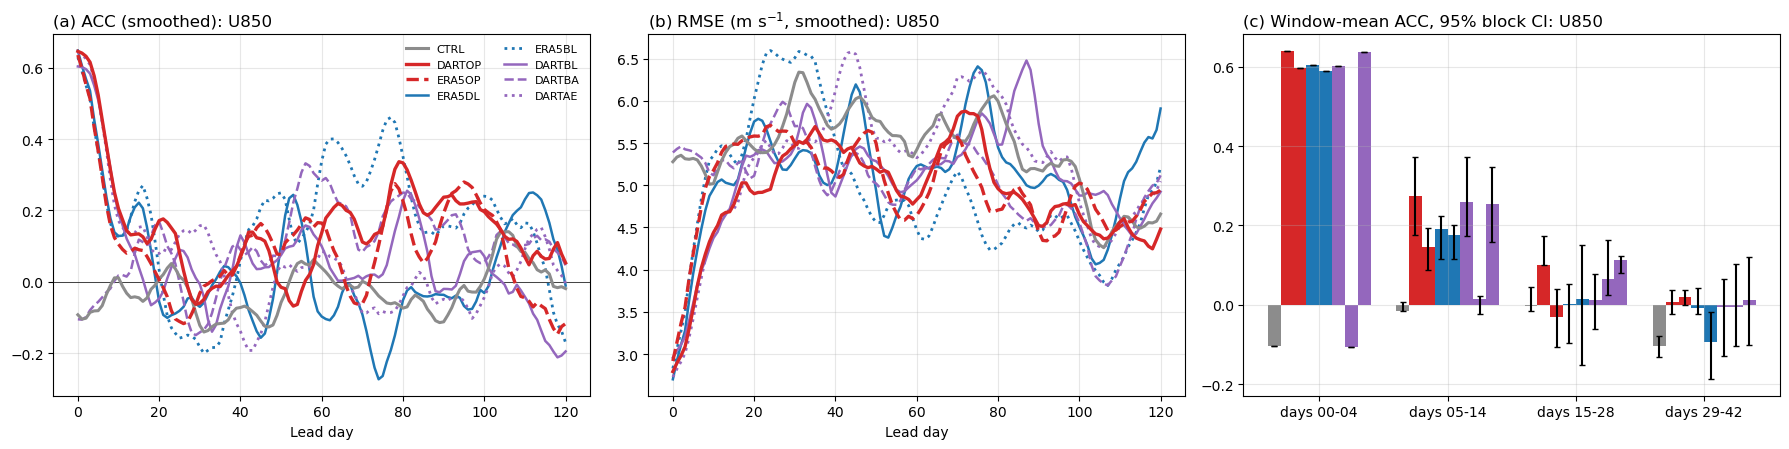

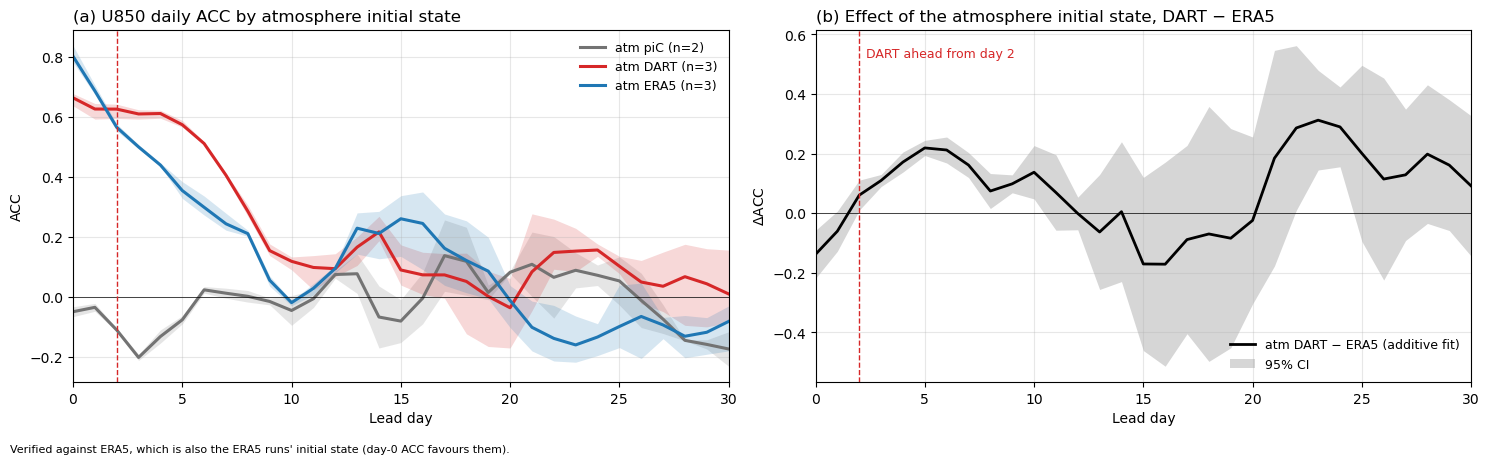

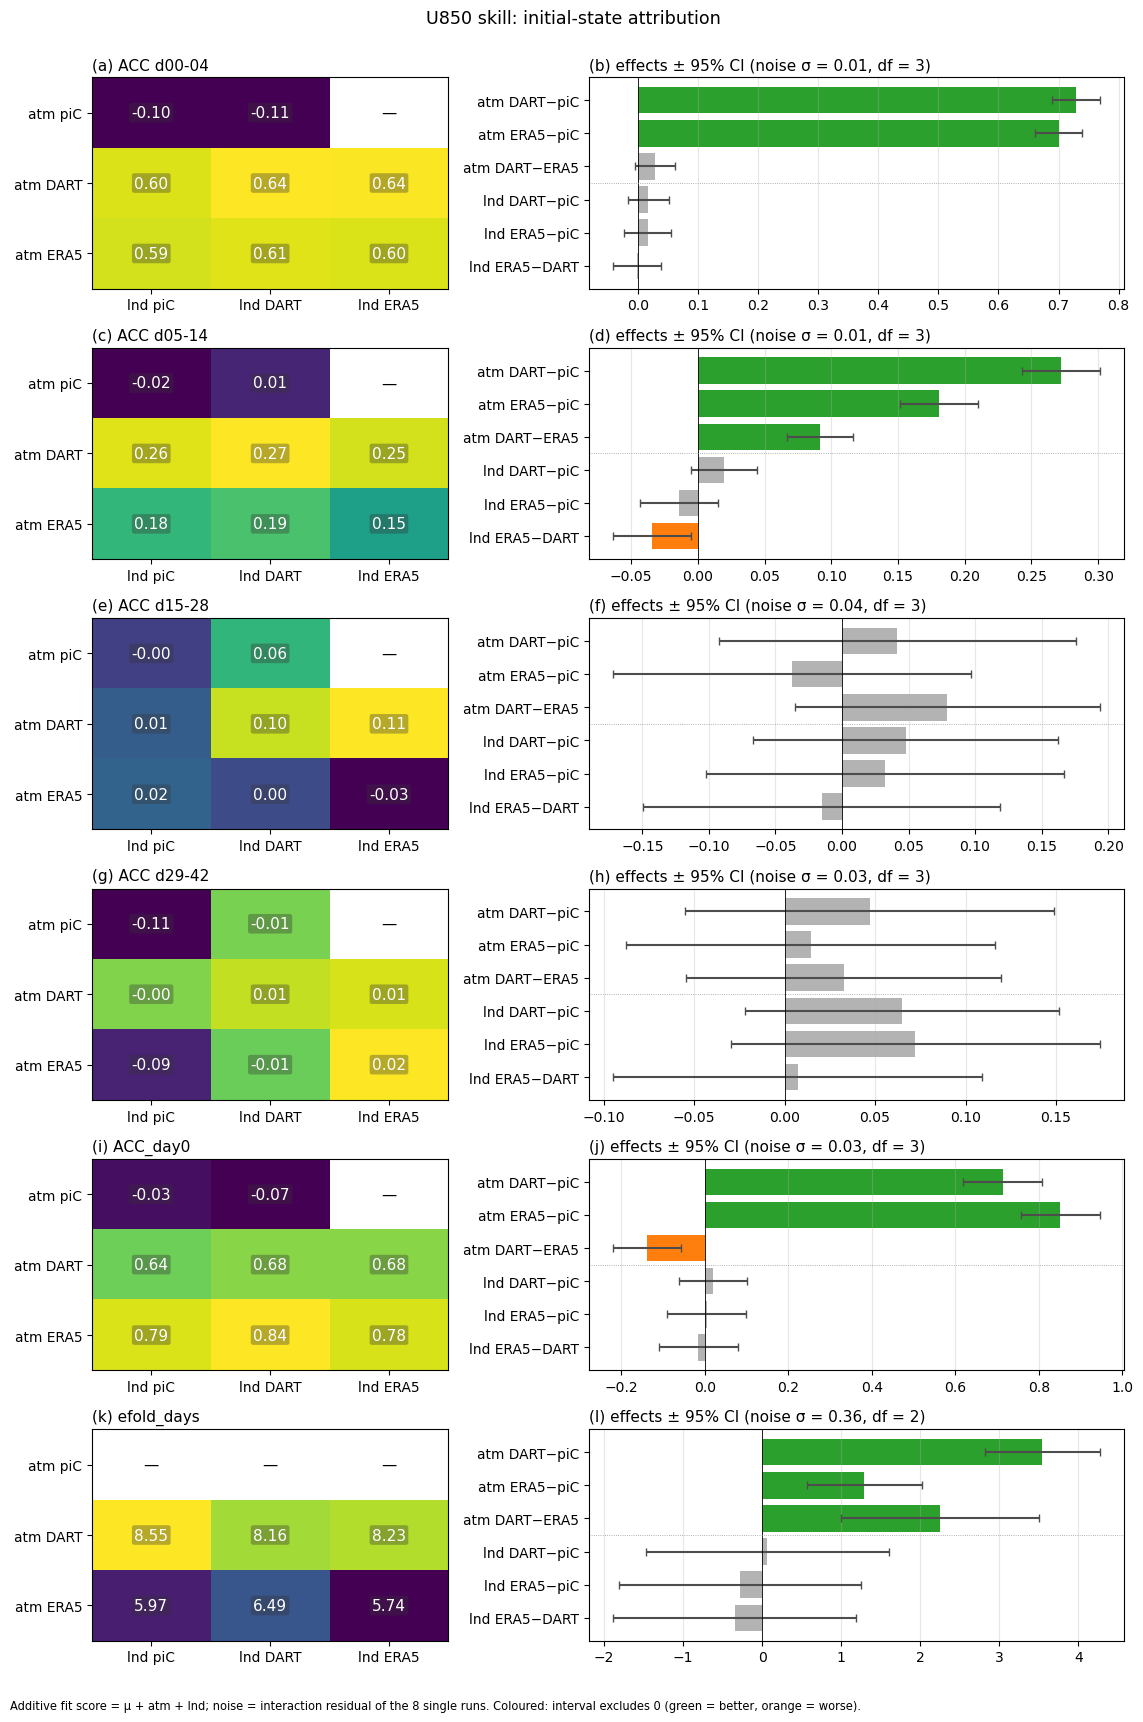

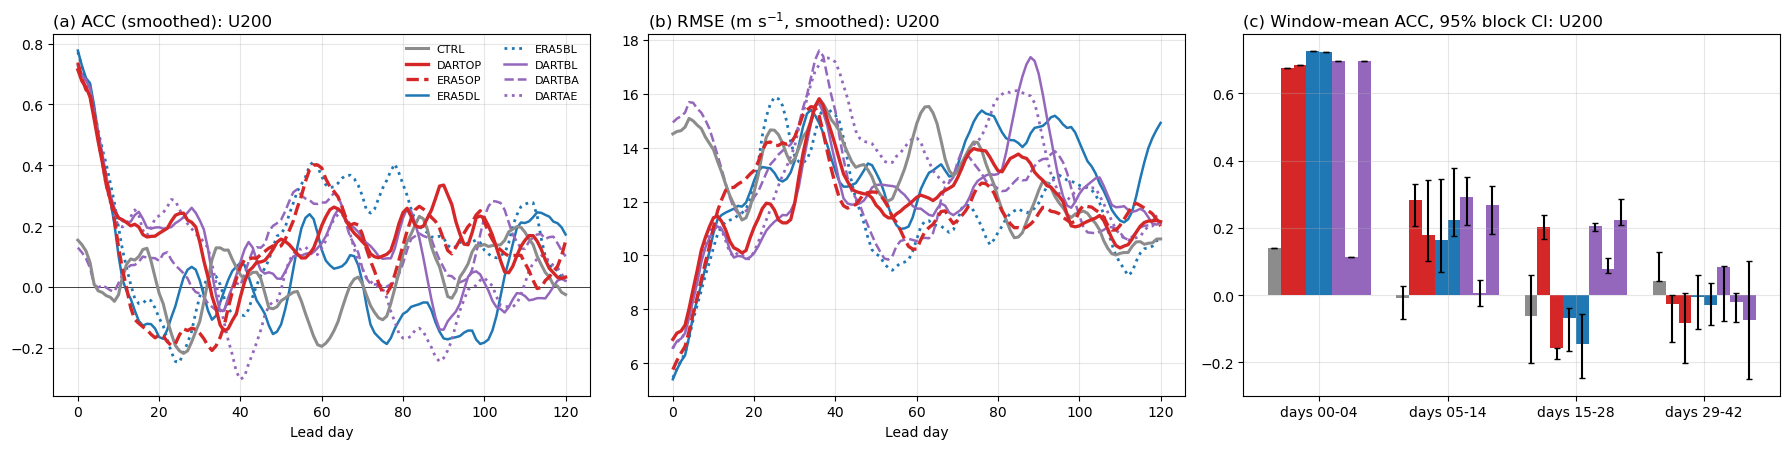

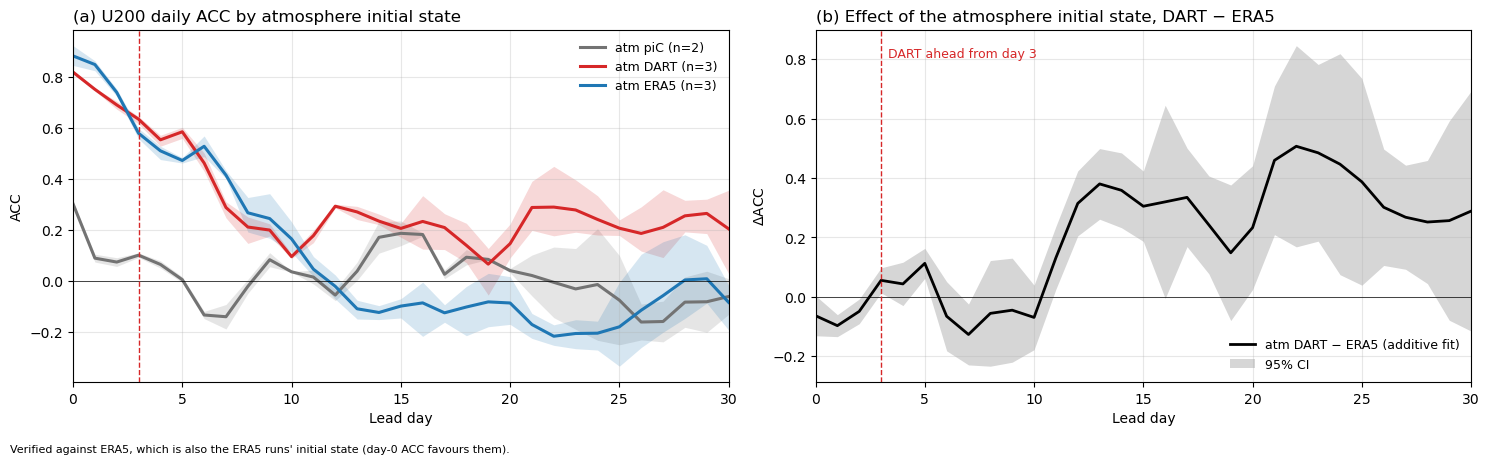

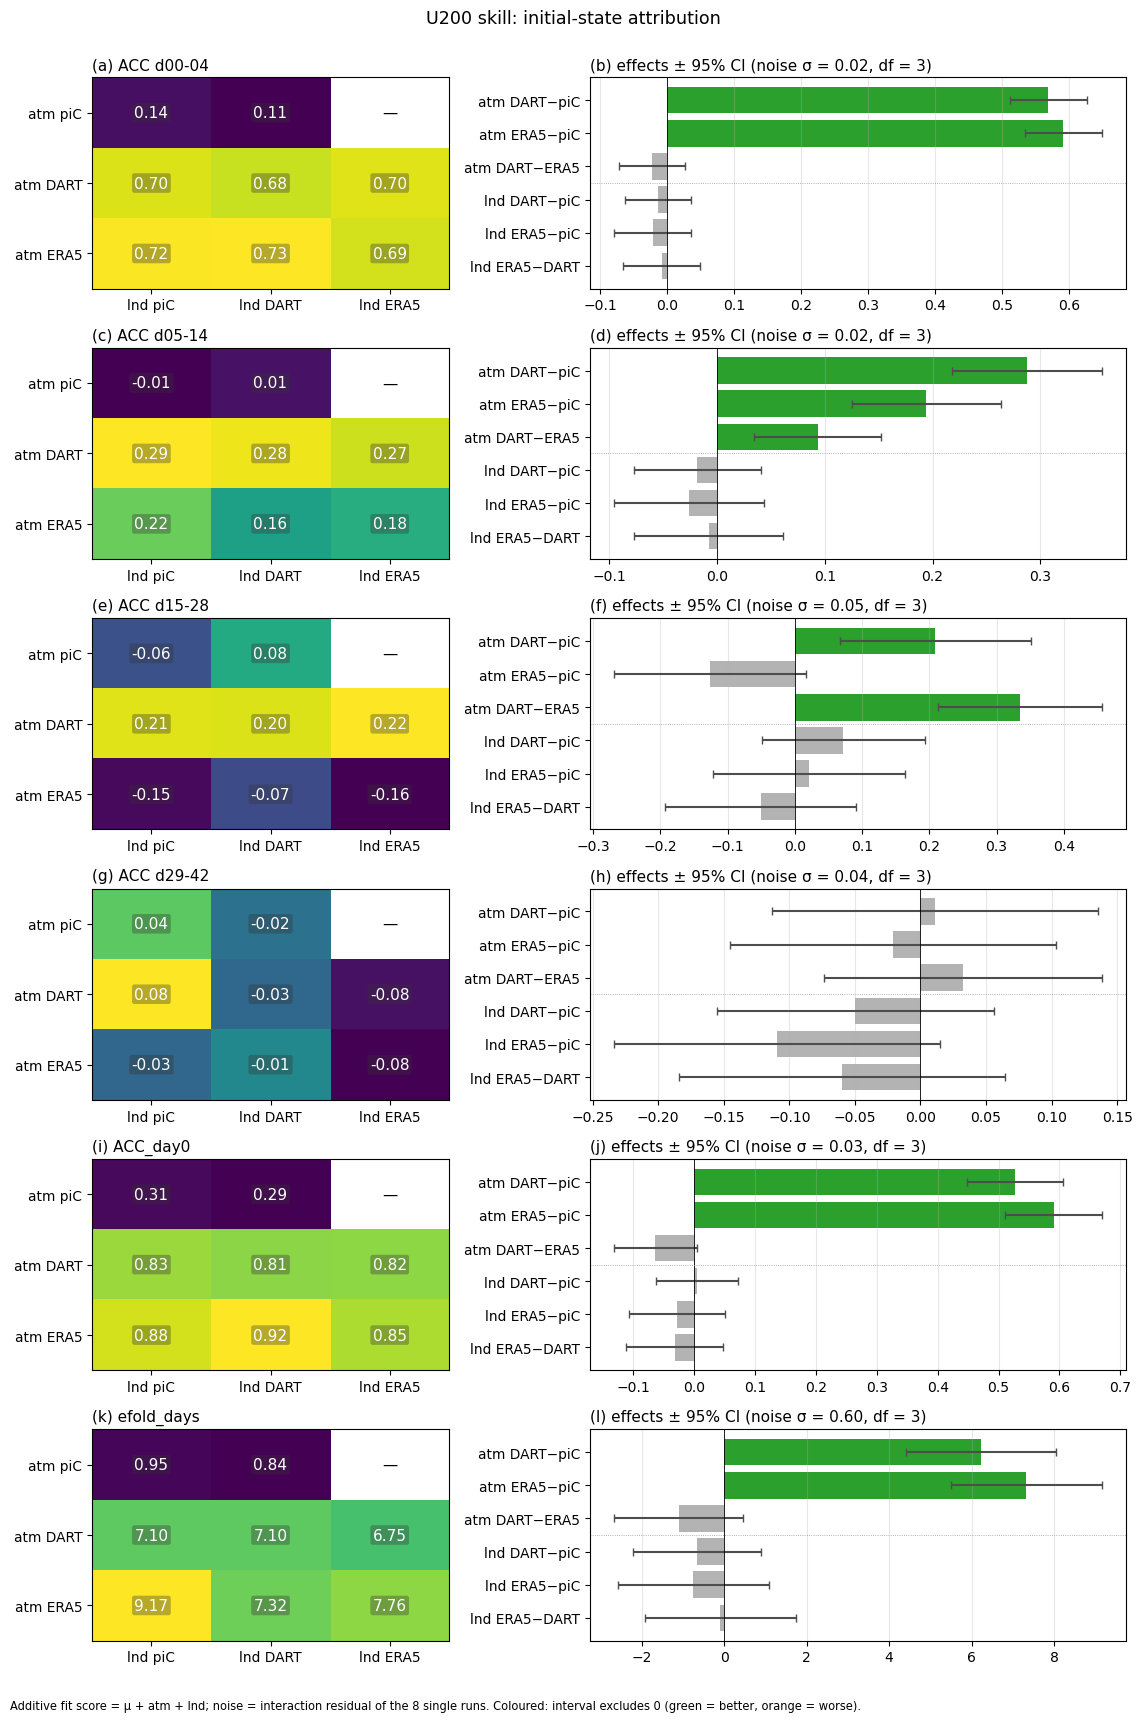

In [8]:
from util.hind_factorial import plot_factorial_scorecard
from util.tropical_wind_skill import plot_wind_skill, plot_wind_skill_groups

for var, sk in skills.items():
    save(plot_wind_skill(sk, table[table.variable == var], var), f"wind_skill_{var}.png")
    save(plot_wind_skill_groups(sk, var, max_lead=GROUP_MAX_LEAD), f"wind_skill_groups_{var}.png")
    s = scores[var]
    save(plot_factorial_scorecard(s, effects[effects.variable == var], title=f"{var} skill: initial-state attribution",
                                  higher_is_better={c: True for c in s.columns}),
         f"wind_skill_factorial_{var}.png")